# FIN 6465 — Chapter 2 Mini-Project
## Historical Data Pack & EDA Notebook

**Financial Modeling with Python — Chapter 2: Fundamentals of Financial Statement Analysis**

> **Guiding question:** What is the firm's recent financial story, and which drivers should carry forward into forecasting assumptions?

**Due:** Friday, October 23, 11:59 PM ET &nbsp;|&nbsp; **Points:** 10 &nbsp;|&nbsp; **Submit:** this notebook (`.ipynb`) in Canvas → Assignments

Read the **Chapter 2 Mini-Project Brief (PDF)** on the Week 2 page first. Section numbers in this notebook match the brief.

**Updated template (quarterly data).** The data pack now uses **at least five years of quarterly data** (at least 20 quarters of 10-Q/10-K statements). Ratios use trailing-twelve-month (TTM) flows; fiscal-year totals are built from the quarters with the provided `to_fiscal_years` helper.

### Student information

| | |
|---|---|
| **Name** | Caleb D'Antonio |
| **UF email** | c.dantonio@ufl.edu |
| **Section** | R222 (4:05 PM) |
| **Team members** | Casey Foran, Sophia Parra, Aman Vyas |
| **Team company (ticker)** | Quanta Services, Inc. (PWR) |
| **Generative AI tools used** | Claude |

**Collaboration.** Your team works on the same company and may work through the mini-project together, but **each student submits their own notebook and is graded individually**. Write your own code and your own interpretations.

**Generative AI.** You may use AI tools to understand concepts and debug code if you disclose it in the AI-use reflection. Be ready to explain every line you submit: **next Tuesday's quiz includes questions on this mini-project.**

### How to use this notebook

1. Work top to bottom and complete every `# TODO`. This week provides function names, docstrings, and structure; you write the logic. Chart and table formatting code is provided.
2. Put **all inputs in the assumptions cell**. Company data comes from the FMP API; do not type it in by hand.
3. Answer every ✍️ prompt in its markdown cell.
4. Before submitting, run **Kernel → Restart Kernel and Run All Cells**. The notebook must run top to bottom without errors.
5. Save as **`FIN6465_MP2_LastName_FirstName.ipynb`** and upload it in Canvas.

---
## Setup

Run these cells to check your environment and load the FMP helper and the quarterly helpers. `fmp_get` now pulls **quarterly** statements by default (`period="quarter"`); pass `period="annual"` only when you need a 10-K figure, as in the tie-out check. The key setup is the same as Week 1; if `FMP_API_KEY` is already set, nothing else is needed.

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print(f"Python     {sys.version.split()[0]}")
print(f"NumPy      {np.__version__}")
print(f"pandas     {pd.__version__}")
print(f"Matplotlib {matplotlib.__version__}")

Python     3.13.9
NumPy      2.1.3
pandas     2.2.3
Matplotlib 3.10.0


In [2]:
import os, json
from pathlib import Path
from getpass import getpass
import requests

FMP_BASE = "https://financialmodelingprep.com/stable"
CACHE_DIR = Path("fmp_cache")
CACHE_DIR.mkdir(exist_ok=True)

FMP_API_KEY = os.environ.get("FMP_API_KEY") or getpass("Paste your team's FMP API key (input is hidden): ")


def fmp_get(endpoint, symbol, period="quarter", limit=24, use_cache=True):
    """Fetch one FMP endpoint for a ticker and return a DataFrame (most recent period first).

    endpoint : "income-statement", "balance-sheet-statement", "cash-flow-statement", or "key-metrics"
    symbol   : ticker, e.g. "AAPL"
    period   : "quarter" (10-Q; the course default) or "annual" (10-K)
    limit    : number of periods to return (24 quarters by default; at least 20 are required)
    """
    symbol = symbol.upper().strip()
    cache_file = CACHE_DIR / f"{symbol}_{endpoint}_{period}_{limit}.json"
    if use_cache and cache_file.exists():
        data = json.loads(cache_file.read_text())
    else:
        params = {"symbol": symbol, "period": period, "limit": limit, "apikey": FMP_API_KEY}
        response = requests.get(f"{FMP_BASE}/{endpoint}", params=params, timeout=30)
        if response.status_code != 200:
            raise RuntimeError(f"FMP returned HTTP {response.status_code}: {response.text[:300]}")
        data = response.json()
        if isinstance(data, dict):   # FMP reports problems as a JSON object
            raise RuntimeError(f"FMP error for {symbol}: {data}")
        if not data:
            raise ValueError(f"No data returned for {symbol} ({endpoint}). Check the ticker.")
        cache_file.write_text(json.dumps(data))
    return pd.DataFrame(data)


def pick(df, field, row=0):
    """Return one value from an FMP statement: `field` in row `row` (0 = most recent period)."""
    if field not in df.columns:
        raise KeyError(f"'{field}' is not a column. Look at df.columns to find the right field name.")
    value = df.iloc[row][field]
    if pd.isna(value):
        raise ValueError(f"'{field}' is empty for row {row}. Check the filing (10-Q, or 10-K for a fiscal Q4) and choose another field.")
    return float(value)

print("FMP helper ready. API key loaded:", bool(FMP_API_KEY))

Paste your team's FMP API key (input is hidden):  ········


FMP helper ready. API key loaded: True


### Quarterly helpers (provided)

Income-statement and cash-flow lines are **flows** (summed across quarters: four quarters give a trailing-twelve-month, **TTM**, figure); balance-sheet lines are **stocks** (read at a quarter-end). `to_fiscal_years` sums flows and takes the Q4 balance for stocks, keeping only complete fiscal years.

In [3]:
# ---- Quarterly helpers (provided) -------------------------------------------------
# Every mini-project uses at least five years of QUARTERLY data (20 quarters of 10-Q/10-K
# filings). Flows (revenue, net income, CFO, CapEx, ...) are summed across quarters;
# stocks (balance-sheet items) are read at a quarter-end date.
MIN_QUARTERS = 20   # course requirement: at least 5 years x 4 quarters


def quarterly_frame(df, scale=1.0):
    """Return an FMP quarterly statement sorted oldest -> newest, indexed by labels like 'FY2025Q3'.

    Adds three columns: fiscal_year (int), fiscal_q (1-4) and period_end (Timestamp).
    Numeric columns are divided by `scale` (1e6 -> USD millions); ratios such as EPS are not
    special-cased, so divide only the statements you need in dollars.
    """
    out = df.copy()
    if "fiscalYear" in out.columns:
        fy = out["fiscalYear"].astype(int)
    else:
        fy = pd.to_datetime(out["date"]).dt.year
    q = out["period"].astype(str).str.upper().str.replace("Q", "", regex=False)
    if not q.isin(["1", "2", "3", "4"]).all():
        raise ValueError("Expected period values Q1-Q4. Did you call fmp_get(..., period='quarter')?")
    out["fiscal_year"] = fy.values
    out["fiscal_q"] = q.astype(int).values
    out["period_end"] = pd.to_datetime(out["date"]).values
    out = out.sort_values(["fiscal_year", "fiscal_q"])
    out.index = [f"FY{y}Q{qq}" for y, qq in zip(out["fiscal_year"], out["fiscal_q"])]
    keep = {"fiscal_year", "fiscal_q", "period_end"}
    num = [c for c in out.columns if c not in keep and pd.api.types.is_numeric_dtype(out[c])]
    out[num] = out[num] / scale
    return out


def check_quarters(q, min_quarters=MIN_QUARTERS):
    """PASS/FAIL detail for the quarterly coverage rule: enough quarters, unique, no gaps."""
    n = len(q)
    unique = q.index.is_unique
    seq = q["fiscal_year"] * 4 + q["fiscal_q"]
    no_gaps = bool((seq.diff().dropna() == 1).all())
    passed = (n >= min_quarters) and unique and no_gaps
    detail = f"{n} quarters ({q.index[0]} to {q.index[-1]}); unique={unique}; consecutive={no_gaps}"
    return passed, detail


def ttm(series):
    """Trailing-twelve-month sum of a quarterly FLOW series (NaN until four quarters exist)."""
    return series.rolling(4).sum()


def to_fiscal_years(q, flow_cols=(), stock_cols=()):
    """Aggregate quarters to complete fiscal years: flows are summed, stocks use the Q4 value.

    Only fiscal years with all four quarters are returned, so a partial current year is dropped.
    """
    complete = q.groupby("fiscal_year")["fiscal_q"].nunique()
    years = complete[complete == 4].index
    qq = q[q["fiscal_year"].isin(years)]
    parts = []
    if flow_cols:
        parts.append(qq.groupby("fiscal_year")[list(flow_cols)].sum())
    if stock_cols:
        parts.append(qq[qq["fiscal_q"] == 4].set_index("fiscal_year")[list(stock_cols)])
    out = pd.concat(parts, axis=1)
    out.index.name = "fiscal_year"
    return out

### Assumptions (all inputs live here)

In [4]:
# ===================== ASSUMPTIONS =====================
SYMBOL = "PWR"           # Quanta Services
N_QUARTERS = 24          # >= 20 required (5 years); 24 guarantees 5 complete fiscal years
SCALE = 1e6              # FMP reports whole dollars; divide by SCALE for USD millions
UNITS = "USD millions"
DAYS = 365               # day-count convention for efficiency ratios (applied to TTM flows)

# Field map: model name -> (statement, FMP field). Section 2 lists every available field;
# confirm each one exists for your company and edit any that FMP names differently.
FIELD_MAP = {
    # income statement
    "revenue":            ("income", "revenue"),
    "cogs":               ("income", "costOfRevenue"),
    "gross_profit":       ("income", "grossProfit"),
    "sga":                ("income", "sellingGeneralAndAdministrativeExpenses"),
    "ebit":               ("income", "operatingIncome"),
    "ebitda":             ("income", "ebitda"),
    "interest_expense":   ("income", "interestExpense"),
    "net_income":         ("income", "netIncome"),
    # balance sheet
    "cash_sti":           ("balance", "cashAndShortTermInvestments"),
    "receivables":        ("balance", "netReceivables"),
    "inventory":          ("balance", "inventory"),
    "current_assets":     ("balance", "totalCurrentAssets"),
    "ppe_net":            ("balance", "propertyPlantEquipmentNet"),
    "total_assets":       ("balance", "totalAssets"),
    "payables":           ("balance", "accountPayables"),
    "current_liabilities":("balance", "totalCurrentLiabilities"),
    "total_debt":         ("balance", "totalDebt"),
    "total_liabilities":  ("balance", "totalLiabilities"),
    "total_equity":       ("balance", "totalEquity"),
    # cash flow statement
    "cfo":                ("cashflow", "operatingCashFlow"),
    "capex":              ("cashflow", "capitalExpenditure"),
    "cash_begin":         ("cashflow", "cashAtBeginningOfPeriod"),
    "cash_end":           ("cashflow", "cashAtEndOfPeriod"),
    "net_change_cash":    ("cashflow", "netChangeInCash"),
    "acquisitions":       ("cashflow", "acquisitionsNet"),
    # market data (valuation multiples)
    "market_cap":         ("metrics", "marketCap"),
    "enterprise_value":   ("metrics", "enterpriseValue"),
}

---
## 2 Inputs: Build the Historical Data Pack

Pull at least five years of **quarterly** statements (`N_QUARTERS`, at least 20) plus quarterly market data (`key-metrics`, for the valuation multiples). The cache file name includes the period and limit, so these quarterly pulls are new API calls even if you ran Week 1 in the same folder; after the first run they load from your cache.

In [5]:
statements = {
    "income":   fmp_get("income-statement", SYMBOL, period="quarter", limit=N_QUARTERS),
    "balance":  fmp_get("balance-sheet-statement", SYMBOL, period="quarter", limit=N_QUARTERS),
    "cashflow": fmp_get("cash-flow-statement", SYMBOL, period="quarter", limit=N_QUARTERS),
    "metrics":  fmp_get("key-metrics", SYMBOL, period="quarter", limit=N_QUARTERS),
}
source_cols = ["date", "fiscalYear", "period", "filingDate", "reportedCurrency"]
display(statements["income"][[c for c in source_cols if c in statements["income"].columns]])

,date,fiscalYear,period,filingDate,reportedCurrency
0,2026-06-30,2026,Q2,2026-07-30,USD
1,2026-03-31,2026,Q1,2026-04-30,USD
2,2025-12-31,2025,Q4,2026-02-19,USD
3,2025-09-30,2025,Q3,2025-10-30,USD
4,2025-06-30,2025,Q2,2025-07-31,USD
5,2025-03-31,2025,Q1,2025-05-01,USD
6,2024-12-31,2024,Q4,2025-02-20,USD
7,2024-09-30,2024,Q3,2024-10-31,USD
8,2024-06-30,2024,Q2,2024-08-01,USD
9,2024-03-31,2024,Q1,2024-05-02,USD


In [6]:
# Every available field, by statement: use this to confirm FIELD_MAP
for name, df in statements.items():
    print(f"{name}:\n{list(df.columns)}\n")

income:
['date', 'symbol', 'reportedCurrency', 'cik', 'filingDate', 'acceptedDate', 'fiscalYear', 'period', 'revenue', 'costOfRevenue', 'grossProfit', 'researchAndDevelopmentExpenses', 'generalAndAdministrativeExpenses', 'sellingAndMarketingExpenses', 'sellingGeneralAndAdministrativeExpenses', 'otherExpenses', 'operatingExpenses', 'costAndExpenses', 'netInterestIncome', 'interestIncome', 'interestExpense', 'depreciationAndAmortization', 'ebitda', 'ebit', 'nonOperatingIncomeExcludingInterest', 'operatingIncome', 'totalOtherIncomeExpensesNet', 'incomeBeforeTax', 'incomeTaxExpense', 'netIncomeFromContinuingOperations', 'netIncomeFromDiscontinuedOperations', 'otherAdjustmentsToNetIncome', 'netIncome', 'netIncomeDeductions', 'bottomLineNetIncome', 'eps', 'epsDiluted', 'weightedAverageShsOut', 'weightedAverageShsOutDil']

balance:
['date', 'symbol', 'reportedCurrency', 'cik', 'filingDate', 'acceptedDate', 'fiscalYear', 'period', 'cashAndCashEquivalents', 'shortTermInvestments', 'cashAndShort

Write `build_data_pack()` to turn the four raw FMP tables into **one tidy quarterly DataFrame**: one row per fiscal quarter (oldest first, labeled like `FY2025Q3`), one column per model name in `FIELD_MAP`, dollar amounts in `UNITS`, plus the bookkeeping columns `fiscal_year`, `fiscal_q`, and `period_end` that the quarterly helpers need.

In [7]:
def build_data_pack(statements, field_map, scale):
    """Combine FMP statements into one tidy table.

    Parameters
    ----------
    statements : dict of DataFrames keyed by "income", "balance", "cashflow", "metrics"
    field_map  : dict mapping model name -> (statement key, FMP field)
    scale      : divide every dollar amount by this (1e6 -> USD millions)

    Returns
    -------
    DataFrame indexed by fiscal quarter ("FY2025Q3", oldest first): the columns fiscal_year,
    fiscal_q, and period_end, then one column per model name.
    """
    frames = {key: quarterly_frame(df, scale) for key, df in statements.items()}
    columns = {name: frames[stmt][field] for name, (stmt, field) in field_map.items()}
    meta = frames["income"][["fiscal_year", "fiscal_q", "period_end"]]
    return pd.concat([meta, pd.DataFrame(columns)], axis=1).sort_index()

data = build_data_pack(statements, FIELD_MAP, SCALE)
display(data.T.round(1))

,FY2020Q3,FY2020Q4,FY2021Q1,FY2021Q2,FY2021Q3,FY2021Q4,FY2022Q1,FY2022Q2,FY2022Q3,FY2022Q4,...,FY2024Q1,FY2024Q2,FY2024Q3,FY2024Q4,FY2025Q1,FY2025Q2,FY2025Q3,FY2025Q4,FY2026Q1,FY2026Q2
fiscal_year,2020,2020,2021,2021,2021,2021,2022,2022,2022,2022,...,2024,2024,2024,2024,2025,2025,2025,2025,2026,2026
fiscal_q,3,4,1,2,3,4,1,2,3,4,...,1,2,3,4,1,2,3,4,1,2
period_end,2020-09-30 00:00:00,2020-12-31 00:00:00,2021-03-31 00:00:00,2021-06-30 00:00:00,2021-09-30 00:00:00,2021-12-31 00:00:00,2022-03-31 00:00:00,2022-06-30 00:00:00,2022-09-30 00:00:00,2022-12-31 00:00:00,...,2024-03-31 00:00:00,2024-06-30 00:00:00,2024-09-30 00:00:00,2024-12-31 00:00:00,2025-03-31 00:00:00,2025-06-30 00:00:00,2025-09-30 00:00:00,2025-12-31 00:00:00,2026-03-31 00:00:00,2026-06-30 00:00:00
revenue,3020.161,2912.185,2703.581,2999.816,3353.278,3923.538,3965.525,4232.003,4459.757,4416.618,...,5031.819,5594.387,6493.167,6553.422,6233.334,6773.007,7505.141,7840.0,7874.787,9556.997
cogs,2532.334,2467.642,2352.046,2573.396,2841.374,3425.504,3533.105,3715.358,3838.074,3812.184,...,4485.836,4862.27,5591.019,5605.868,5508.859,5878.611,6414.974,6855.0,6767.458,8011.819
gross_profit,487.827,444.543,351.535,426.42,511.904,498.034,432.42,516.645,621.683,604.434,...,545.983,732.117,902.148,947.554,724.475,894.396,1090.167,985.0,1107.329,1545.178
sga,240.054,252.04,243.352,270.11,274.846,367.648,309.756,309.054,307.586,336.957,...,389.369,423.211,476.163,501.647,480.191,503.756,572.95,500.0,620.726,698.49
ebit,247.773,192.503,108.183,156.31,237.058,130.386,122.664,207.591,314.097,267.476999,...,156.614,308.906,425.985,445.907,244.284,390.64,517.217,485.0,334.222,694.834
ebitda,321.157,264.432,200.98,257.079,338.626,316.01,303.017,347.955,403.426,418.471,...,354.665,475.269,641.793,685.312,450.837,590.105,771.32,769.432,595.298,964.806
interest_expense,11.049,11.304,12.475,13.109,17.259,26.056,24.728,28.639,33.566,37.43,...,41.072,45.321,59.95,56.344,54.312,59.579,71.806,75.748,73.267,73.548


**Fiscal years and TTM (provided).** `annual` aggregates the quarters to complete fiscal years (flows summed, stocks at Q4; `cash_begin` comes from Q1). `data_ttm` replaces each flow with its trailing-twelve-month sum and keeps quarter-end balances, so ratios are annual-equivalent every quarter. At a fiscal Q4, the TTM figure equals the fiscal-year figure.

In [8]:
# Flows come from the income and cash-flow statements; balances and market values are stocks.
FLOW_COLS = [m for m, (stmt, _) in FIELD_MAP.items()
             if stmt in ("income", "cashflow") and m not in ("cash_begin", "cash_end")]
STOCK_COLS = [m for m, (stmt, _) in FIELD_MAP.items() if stmt in ("balance", "metrics")] + ["cash_end"]

annual = to_fiscal_years(data, flow_cols=FLOW_COLS, stock_cols=STOCK_COLS)
annual["cash_begin"] = data[data["fiscal_q"] == 1].set_index("fiscal_year")["cash_begin"].reindex(annual.index)

data_ttm = data.copy()
data_ttm[FLOW_COLS] = data[FLOW_COLS].apply(ttm)     # NaN for the first three quarters

print(f"{len(data)} quarters ({data.index[0]} to {data.index[-1]}); "
      f"complete fiscal years: {list(annual.index)}")
display(annual.T.round(1))

24 quarters (FY2020Q3 to FY2026Q2); complete fiscal years: [2021, 2022, 2023, 2024, 2025]


fiscal_year,2021,2022,2023,2024,2025
revenue,12980.2,17073.9,20882.2,23672.8,28351.5
cogs,11192.3,14898.7,18234.1,20545.0,24657.4
gross_profit,1787.9,2175.2,2648.1,3127.8,3694.0
sga,1156.0,1263.4,1513.8,1790.4,2056.9
ebit,631.9,911.8,1134.3,1337.4,1637.1
ebitda,1112.7,1472.9,1770.7,2157.0,2581.7
interest_expense,68.9,124.4,186.9,202.7,261.4
net_income,486.0,491.2,744.7,904.8,1028.4
cfo,582.4,1130.3,1576.0,2081.2,2230.0
capex,-386.7,-428.8,-442.8,-604.1,-609.2


---
## 3.1 Data Quality and Alignment Checks

> **Comparability first.** Confirm that periods are comparable (same fiscal year-end, consistent definitions, restatements handled) before computing any ratio.

`check()` records each test as PASS or FAIL. Write the five checks below; the integrity checks apply to **every quarter**.

In [9]:
checks = []

def check(name, passed, detail=""):
    """Record a data-quality check as PASS/FAIL with an optional detail."""
    checks.append({"check": name, "result": "PASS" if passed else "FAIL", "detail": detail})

annual_10k = fmp_get("income-statement", SYMBOL, period="annual", limit=5)   # provided: 10-K figures

# 1: quarterly coverage: at least 20 quarters, unique and consecutive
passed, detail = check_quarters(data)
check("Quarterly coverage (>= 20, unique, consecutive)", passed, detail)

# 2: no missing values (FMP reports a missing line as 0, so flag zeros too;
#    acquisitions can truly be 0 in a quarter with no deals, so only blanks count there)
model_cols = list(FIELD_MAP)
gaps = [c for c in model_cols if data[c].isna().any()
        or (c != "acquisitions" and (data[c] == 0).any())]
check("No missing or zero values", len(gaps) == 0,
      ", ".join(gaps) if gaps else "none")

# 3: balance sheet identity within 0.5% of total assets, every quarter
bs_gap = (data["total_assets"] - (data["total_liabilities"] + data["total_equity"])).abs()
check("Assets = Liabilities + Equity (0.5% tolerance)",
      (bs_gap <= 0.005 * data["total_assets"]).all(),
      f"max gap {bs_gap.max():.1f} {UNITS}")

# 4: cash roll-forward within 1 unit, every quarter
cash_gap = (data["cash_begin"] + data["net_change_cash"] - data["cash_end"]).abs()
check("Cash roll-forward (tolerance 1)",
      (cash_gap <= 1).all(),
      f"max gap {cash_gap.max():.1f} {UNITS}")

# 5: quarter-to-annual tie-out: latest complete fiscal year's four quarters vs. the 10-K
fy = annual.index[-1]
row = annual_10k[annual_10k["fiscalYear"].astype(int) == int(fy)]
rev_10k = float(row["revenue"].iloc[0]) / SCALE
rev_q = annual.loc[fy, "revenue"]
check(f"FY{fy} revenue: sum of quarters ties to 10-K (0.5%)",
      abs(rev_q - rev_10k) <= 0.005 * rev_10k,
      f"quarters {rev_q:,.1f} vs 10-K {rev_10k:,.1f} {UNITS}")

pd.DataFrame(checks)

,check,result,detail
0,"Quarterly coverage (>= 20, unique, consecutive)",PASS,24 quarters (FY2020Q3 to FY2026Q2); unique=Tru...
1,No missing or zero values,PASS,none
2,Assets = Liabilities + Equity (0.5% tolerance),PASS,max gap 0.0 USD millions
3,Cash roll-forward (tolerance 1),PASS,max gap 0.0 USD millions
4,FY2025 revenue: sum of quarters ties to 10-K (...,PASS,"quarters 28,351.5 vs 10-K 28,351.5 USD millions"


✍️ **Data notes:** List any missing fields, restatements, reclassifications, or `FIELD_MAP` edits. Confirm the fiscal year-end is the same every year and the quarters are consecutive, and note FMP sign conventions that matter (for example, capital expenditures are negative). Explain any FAIL above.

The data pack covers 24 consecutive quarters (FY2020Q3 to FY2026Q2) from 10-Q filings, with fiscal Q4 figures derived from the 10-K since Quanta files no Q4 10-Q, reported in USD and converted to USD millions. Quanta's fiscal year ends December 31 every year, so fiscal quarters match calendar quarters, and the complete fiscal years are FY2021 to FY2025. Every original FIELD_MAP field exists in PWR's quarterly FMP data; my only edit was adding acquisitions (FMP field acquisitionsNet). No field is missing or reported as zero; acquisitions is excluded from the zero test because a quarter with no deals legitimately reports 0. The balance sheet identity and the cash roll-forward tie in every quarter, and FY2025 revenue summed from its four quarters ties to the 10-K within 0.5%, so all five checks pass. Sign conventions: capital expenditures and acquisitions are negative (cash outflows), net change in cash is signed (negative for FY2024 and FY2025), and interest expense is reported as a positive number. Two definitional notes: cash_sti from the balance sheet differs slightly from cash_end on the cash flow statement (229.1 vs 231.9 at FY2021Q4), likely because the cash flow figure includes restricted cash; and total_equity includes noncontrolling interests while net_income is attributable to Quanta shareholders, which slightly understates ROE. No restatements were identified or adjusted for. Acquisitions affect comparability: Quanta spent $2,594M in FY2021, $1,723M in FY2024, and $3,143M in FY2025, so growth in those years includes acquired revenue, not just organic growth.

---
## 3.2 Common-Size and Trend Diagnostics

Common-size tables use complete **fiscal years** (`annual`) to show structural shifts. Growth uses the **quarters**: each quarter versus the **same quarter a year earlier**, which removes seasonality. The CAGR uses fiscal-year totals.

In [10]:
def common_size(df, lines, base):
    """Express `lines` as a percent of `base` for every period (row).

    Returns a DataFrame (periods x lines) in percent.
    """
    return df[lines].div(df[base], axis=0) * 100


def yoy_growth(df, lines, periods=4):
    """Year-over-year growth in percent for each line: each quarter vs. the same quarter a year
    earlier (periods=4), so the first four quarters are NaN."""
    return df[lines].pct_change(periods) * 100


def cagr(first, last, years):
    """Compound annual growth rate between two values over `years` periods, as a decimal.

    CAGR is undefined if either value is zero or negative: return float("nan") in that case.
    """
    if first <= 0 or last <= 0:
        return float("nan")
    return (last / first) ** (1 / years) - 1


In [11]:
is_lines = ["revenue", "cogs", "gross_profit", "sga", "ebit", "net_income"]
bs_lines = ["cash_sti", "receivables", "inventory", "ppe_net", "payables", "total_debt", "total_equity"]

cs_income = common_size(annual, is_lines, "revenue")          # fiscal years
cs_balance = common_size(annual, bs_lines, "total_assets")     # fiscal year-end (Q4) balances
growth = yoy_growth(data, ["revenue", "gross_profit", "ebit", "net_income", "cfo"])   # quarterly, vs. same quarter a year earlier

span = annual.index[-1] - annual.index[0]                      # years between first and last complete fiscal year
cagr_table = pd.Series({line: cagr(annual[line].iloc[0], annual[line].iloc[-1], span)
                        for line in ["revenue", "ebit", "net_income", "cfo"]}, name=f"CAGR FY{annual.index[0]}-FY{annual.index[-1]}")

# Seasonality (provided): each quarter's share of its fiscal year's revenue, complete fiscal years only
seasonality = (data[data["fiscal_year"].isin(annual.index)]
               .pivot_table(index="fiscal_year", columns="fiscal_q", values="revenue", aggfunc="sum"))
seasonality = seasonality.div(seasonality.sum(axis=1), axis=0) * 100

print("Common-size income statement (% of revenue)");      display(cs_income.T.round(1))
print("Common-size balance sheet (% of total assets)");    display(cs_balance.T.round(1))
print("Year-over-year growth vs. same quarter a year earlier (%)"); display(growth.T.round(1))
print("Multi-year CAGR (fiscal years)");                   display((cagr_table * 100).round(1).to_frame("%"))
print("Seasonality: share of fiscal-year revenue by quarter (%)"); display(seasonality.round(1))

Common-size income statement (% of revenue)


fiscal_year,2021,2022,2023,2024,2025
revenue,100.0,100.0,100.0,100.0,100.0
cogs,86.2,87.3,87.3,86.8,87.0
gross_profit,13.8,12.7,12.7,13.2,13.0
sga,8.9,7.4,7.2,7.6,7.3
ebit,4.9,5.3,5.4,5.6,5.8
net_income,3.7,2.9,3.6,3.8,3.6


Common-size balance sheet (% of total assets)


fiscal_year,2021,2022,2023,2024,2025
cash_sti,1.8,3.2,7.9,4.0,1.8
receivables,32.7,35.3,35.9,34.1,33.6
inventory,0.7,0.8,1.1,1.4,1.5
ppe_net,16.8,16.8,15.9,16.1,15.5
payables,9.7,9.7,12.5,11.2,11.4
total_debt,31.1,29.5,27.5,24.0,25.8
total_equity,39.8,40.1,38.7,39.2,36.2


Year-over-year growth vs. same quarter a year earlier (%)


,FY2020Q3,FY2020Q4,FY2021Q1,FY2021Q2,FY2021Q3,FY2021Q4,FY2022Q1,FY2022Q2,FY2022Q3,FY2022Q4,...,FY2024Q1,FY2024Q2,FY2024Q3,FY2024Q4,FY2025Q1,FY2025Q2,FY2025Q3,FY2025Q4,FY2026Q1,FY2026Q2
revenue,NaN,NaN,NaN,NaN,11.0,34.7,46.7,41.1,33.0,12.6,...,13.6,10.8,15.5,13.3,23.9,21.1,15.6,19.6,26.3,41.1
gross_profit,NaN,NaN,NaN,NaN,4.9,12.0,23.0,21.2,21.4,21.4,...,9.0,11.9,16.3,32.1,32.7,22.2,20.8,4.0,52.8,72.8
ebit,NaN,NaN,NaN,NaN,-4.3,-32.3,13.4,32.8,32.5,105.1,...,15.7,13.8,8.2,33.6,56.0,26.5,21.4,8.8,36.8,77.9
net_income,NaN,NaN,NaN,NaN,7.0,-38.4,-5.7,-24.8,-10.6,55.1,...,24.5,13.4,7.5,44.7,21.9,21.8,15.8,3.4,60.4,96.9
cfo,NaN,NaN,NaN,NaN,-84.4,-9.5,-32.3,-37.2,1820.8,133.3,...,519.5,207.1,82.0,-29.0,2.2,-24.4,-23.8,58.4,61.1,270.4


Multi-year CAGR (fiscal years)


,%
revenue,21.6
ebit,26.9
net_income,20.6
cfo,39.9


Seasonality: share of fiscal-year revenue by quarter (%)


fiscal_q,1,2,3,4
fiscal_year,,,,
2021,20.8,23.1,25.8,30.2
2022,23.2,24.8,26.1,25.9
2023,21.2,24.2,26.9,27.7
2024,21.3,23.6,27.4,27.7
2025,22.0,23.9,26.5,27.7


✍️ **Interpretation (one paragraph):** What are the most material structural shifts and inflection points? Name the lines and periods, and cite your numbers. Note any seasonal pattern (which fiscal quarter is largest?).

Revenue more than doubled from $12,980M in FY2021 to $28,352M in FY2025 (21.6% CAGR), with fiscal-year growth slowing from 31.5% in FY2022 to 13.4% in FY2024 before reaccelerating to 19.8% in FY2025. The first inflection is FY2022: gross margin fell from 13.8% to 12.7% of revenue, and net income grew only 1.1% despite 44.3% EBIT growth (631.9 to 911.8), as interest expense nearly doubled (68.9 to 124.4) along with other below-EBIT charges. Gross margin has since recovered only partially (13.0% in FY2025), yet EBIT margin expanded from 4.9% to 5.8% because SG&A fell from 8.9% to 7.3% of revenue, which is why EBIT (26.9% CAGR) outgrew revenue. Cash flow is the strongest line: CFO grew at a 39.9% CAGR, rising from 1.2x to 2.2x net income, though it slowed to 7.1% growth in FY2025 as receivables jumped 31% against 19.8% revenue growth, partly due to acquisitions. On the balance sheet, receivables consistently make up about a third of total assets, cash peaked at 7.9% of assets in FY2023 before falling back to 1.8% in FY2025, and debt to assets declined from 31.1% to 24.0% through FY2024 before rising to 25.8% in FY2025 as debt grew by $1,940M, which marks the second inflection point. The quarterly data adds a third inflection: revenue grew 41.1% in FY2026Q2 versus the same quarter a year earlier, accelerating from 26.3% in FY2026Q1 and 21.1% in FY2025Q2, while EBIT grew 77.9% and net income 96.9%. Revenue is seasonal: Q1 is the smallest quarter every year at 20.8% to 23.2% of fiscal-year revenue, and Q4 is the largest at about 27.7% from FY2023 to FY2025, with FY2022 the only year Q3 slightly exceeded Q4 (26.1% vs 25.9%).

---
## 3.3 Ratio Toolbox (Five Families)

Write `compute_ratios()` to return one DataFrame (quarters × ratios), computed on `data_ttm`: every **flow** is a **TTM** sum (the last four quarters) and every balance is a **quarter-end** balance. Use **average** balances (this quarter-end and the same quarter-end a year earlier) for ROA, ROE, and the days ratios. The first three quarters have no TTM flows and the first four have no average, so those cells are NaN. Day-count: 365 on TTM flows. At a fiscal Q4, each ratio equals its fiscal-year value. Definitions from Chapter 2 (flows are TTM):

| Family | Ratio | Definition |
|---|---|---|
| Liquidity | Current ratio | current assets ÷ current liabilities |
| | Quick ratio | (cash and short-term investments + receivables) ÷ current liabilities |
| Profitability | Gross margin | gross profit ÷ revenue |
| | EBIT margin | EBIT ÷ revenue |
| | ROA / ROE | TTM net income ÷ average total assets / average equity |
| Efficiency | A/R days | average receivables ÷ (TTM revenue ÷ 365) |
| | Inventory days | average inventory ÷ (TTM COGS ÷ 365) |
| | A/P days | average payables ÷ (TTM COGS ÷ 365) |
| | Cash conversion cycle | inventory days + A/R days − A/P days |
| Leverage / coverage | Debt / EBITDA | total debt ÷ TTM EBITDA |
| | Interest coverage | TTM EBIT ÷ TTM interest expense |
| Valuation | P/E | market cap (quarter-end) ÷ TTM net income |
| | EV / EBITDA | enterprise value (quarter-end) ÷ TTM EBITDA |

FMP reports a missing line as 0, which can produce 0 or infinite ratios. If a ratio does not apply to your company (for example, no inventory or no interest expense), set that column to `np.nan` and explain why below.

In [12]:
def compute_ratios(df, days=365):
    """Compute the Chapter 2 ratio toolbox for every quarter.

    df is the quarterly table with TTM flows and quarter-end balances (data_ttm).
    Returns a DataFrame indexed by quarter with these columns:
    current_ratio, quick_ratio, gross_margin, ebit_margin, roa, roe,
    ar_days, inventory_days, ap_days, ccc, debt_to_ebitda, interest_coverage, pe, ev_ebitda
    (margins, ROA, and ROE in percent).
    """
    avg = lambda col: (df[col] + df[col].shift(4)) / 2     # average of this quarter-end and the same quarter-end a year earlier
    r = pd.DataFrame(index=df.index)
    # liquidity
    r["current_ratio"] = df["current_assets"] / df["current_liabilities"]
    r["quick_ratio"] = (df["cash_sti"] + df["receivables"]) / df["current_liabilities"]

    # profitability (percent; flows are TTM)
    r["gross_margin"] = df["gross_profit"] / df["revenue"] * 100
    r["ebit_margin"] = df["ebit"] / df["revenue"] * 100
    r["roa"] = df["net_income"] / avg("total_assets") * 100
    r["roe"] = df["net_income"] / avg("total_equity") * 100

    # efficiency (days, on TTM flows)
    r["ar_days"] = avg("receivables") / (df["revenue"] / days)
    r["inventory_days"] = avg("inventory") / (df["cogs"] / days)
    r["ap_days"] = avg("payables") / (df["cogs"] / days)
    r["ccc"] = r["inventory_days"] + r["ar_days"] - r["ap_days"]

    # leverage / coverage
    r["debt_to_ebitda"] = df["total_debt"] / df["ebitda"]
    r["interest_coverage"] = df["ebit"] / df["interest_expense"]

    # valuation multiples (quarter-end market values over TTM earnings)
    r["pe"] = df["market_cap"] / df["net_income"]
    r["ev_ebitda"] = df["enterprise_value"] / df["ebitda"]
    return r

In [13]:
ratios = compute_ratios(data_ttm, DAYS)     # TTM flows, quarter-end balances
display(ratios.T.round(2))

,FY2020Q3,FY2020Q4,FY2021Q1,FY2021Q2,FY2021Q3,FY2021Q4,FY2022Q1,FY2022Q2,FY2022Q3,FY2022Q4,...,FY2024Q1,FY2024Q2,FY2024Q3,FY2024Q4,FY2025Q1,FY2025Q2,FY2025Q3,FY2025Q4,FY2026Q1,FY2026Q2
current_ratio,1.69,1.68,1.72,1.75,2.41,1.50,1.51,1.56,1.60,1.63,...,1.36,1.30,1.23,1.30,1.31,1.37,1.34,1.14,1.14,1.10
quick_ratio,1.58,1.57,1.61,1.62,2.31,1.40,1.42,1.45,1.49,1.52,...,1.22,1.16,1.11,1.18,1.18,1.21,1.21,1.01,1.02,0.98
gross_margin,NaN,NaN,NaN,14.70,14.49,13.77,13.12,12.66,12.48,12.74,...,12.54,12.58,12.65,13.21,13.29,13.31,13.51,13.03,13.59,14.42
ebit_margin,NaN,NaN,NaN,6.06,5.80,4.87,4.54,4.51,4.67,5.34,...,5.38,5.41,5.35,5.65,5.73,5.78,5.90,5.77,5.76,6.20
roa,NaN,NaN,NaN,NaN,5.80,4.57,4.46,4.15,3.62,3.73,...,5.19,5.15,4.76,5.18,5.37,5.43,4.89,4.72,4.97,5.55
roe,NaN,NaN,NaN,NaN,12.54,10.27,10.10,9.38,8.81,9.34,...,12.92,12.84,12.39,13.29,13.45,13.45,13.14,12.57,13.43,15.19
ar_days,NaN,NaN,NaN,NaN,106.60,103.67,96.33,91.52,93.86,95.76,...,87.50,91.87,98.77,94.08,87.44,86.80,97.09,94.94,95.87,93.54
inventory_days,NaN,NaN,NaN,NaN,1.81,2.20,2.14,2.14,2.01,2.30,...,3.72,3.71,4.01,3.87,4.12,4.22,4.75,4.67,5.00,4.92
ap_days,NaN,NaN,NaN,NaN,44.59,33.41,32.20,29.94,29.43,31.28,...,31.16,34.98,39.30,36.63,34.17,35.25,39.77,36.48,35.96,38.20
ccc,NaN,NaN,NaN,NaN,63.82,72.46,66.27,63.72,66.45,66.78,...,60.07,60.61,63.49,61.32,57.40,55.77,62.08,63.13,64.92,60.26


✍️ **Interpretation (one paragraph):** For each family, what is the most important finding? Note any ratio you could not compute and why.

All fourteen ratios apply to Quanta. Ratios use TTM flows, so the first three quarters have no TTM values and the average-based ratios (ROA, ROE, and the days ratios) start in FY2021Q3, once a year-earlier balance exists; fiscal Q4 values equal the fiscal-year ratios. Liquidity is the clearest deterioration: the current ratio fell from 1.63 in FY2022 to 1.14 in FY2025 and the quick ratio from 1.52 to 1.01, as current liabilities grew 2.6x (3,406 to 8,716) against 1.8x for current assets. Because inventory is minimal, the quick ratio sits close to the current ratio, meaning liquidity rests almost entirely on receivables rather than cash. Profitability is stable with a slight upward drift: gross margin held in a narrow 12.7% to 13.8% band while EBIT margin rose steadily from 4.87% to 5.77% through SG&A leverage, and ROE recovered from 9.3% in FY2022 to roughly 12.5% to 13.3%, though ROA dipped to 4.72% in FY2025 as total assets grew 33% against 13.7% net income growth. Efficiency is driven by receivables: A/R days stayed between 92 and 96 from FY2022 to FY2025, inventory days doubled but remain under 5, and A/P days lengthened from 31 to 36, keeping the cash conversion cycle steady at 61 to 67 days. Leverage improved from 3.60x Debt/EBITDA in FY2021 to 2.08x in FY2024 before rising to 2.49x in FY2025, while interest coverage fell from 9.17x to 6.26x as interest expense grew 3.8x against 2.6x for EBIT. Valuation expanded sharply: P/E nearly doubled from 33.7x to 62.3x and EV/EBITDA rose from 18.1x to 27.1x, as market cap grew about 4x against roughly 2x for net income, indicating the market is pricing in growth well beyond the historical trend. Through FY2026Q2 on a TTM basis, profitability strengthened further (gross margin 14.42%, EBIT margin 6.20%, ROE 15.19%), Debt/EBITDA eased to 2.13x and coverage rose to 6.90x, while liquidity weakened again (current ratio 1.10, quick ratio 0.98) and multiples expanded to 80.9x P/E and 36.9x EV/EBITDA. One outlier: the current ratio spiked to 2.41 in FY2021Q3 alongside Debt/EBITDA jumping from 1.54x to 3.01x, likely cash raised ahead of the Blattner acquisition that closed the following quarter.

---
## 3.4 Dashboard and Red-Flag Logic

The heat map (provided) shows one column per **fiscal year-end** (the Q4 TTM ratios, which equal the fiscal-year ratios) plus the **latest quarter** (TTM) if it is not a Q4. It shades each ratio relative to its own range across those columns, so you can see which ratios moved most and when; the full quarterly history is in the `ratios` table above. Shading shows level, not good or bad: a dark cell is high for that ratio, which is good for coverage but bad for Debt/EBITDA. Rows that do not move are shaded mid-blue. Blank cells have no data (for example, average-based ratios in the first fiscal year).

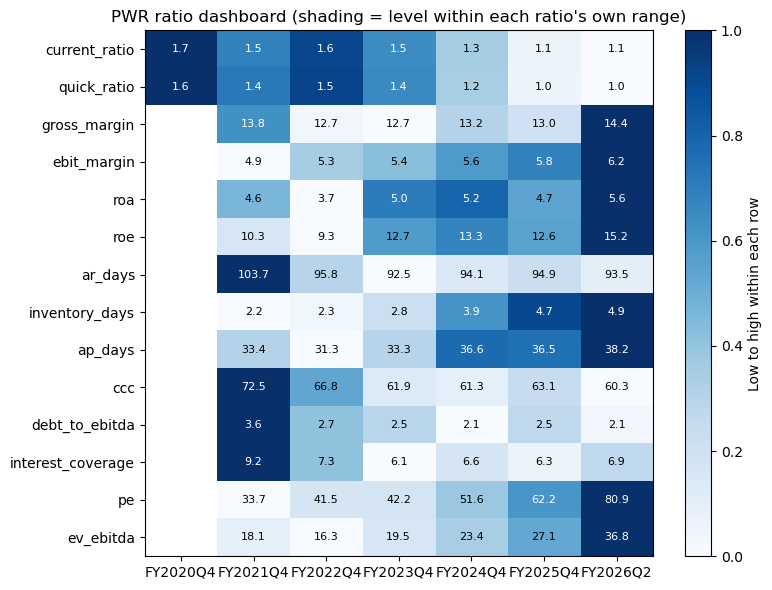

In [14]:
# Heat map (provided): fiscal year-ends (Q4 TTM = fiscal year) plus the latest quarter,
# each row scaled to its own min-max range across those columns
dash = ratios[(data["fiscal_q"] == 4) | (ratios.index == ratios.index[-1])].dropna(how="all")

def scale_row(s):
    spread = s.max() - s.min()
    if pd.isna(spread) or spread <= 1e-9 * max(abs(s.mean()), 1):   # flat row: no meaningful movement
        return s * 0 + 0.5
    return (s - s.min()) / spread
scaled = dash.apply(scale_row)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(scaled.T.values.astype(float), cmap="Blues", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(len(dash.index)), dash.index)
ax.set_yticks(range(len(dash.columns)), dash.columns)
for i, col in enumerate(dash.columns):
    for j, yr in enumerate(dash.index):
        val = dash.loc[yr, col]
        if pd.notna(val):
            dark = scaled.loc[yr, col] > 0.6
            ax.text(j, i, f"{val:,.1f}", ha="center", va="center", fontsize=8, color="white" if dark else "black")
ax.set_title(f"{SYMBOL} ratio dashboard (shading = level within each ratio's own range)")
fig.colorbar(im, ax=ax, label="Low to high within each row")
plt.tight_layout()
plt.show()

**Red flags.** Write **3–5 rules** that highlight where to investigate first. Each rule should be a threshold (for example, interest coverage below 3×) or a direction (for example, A/R days up more than 10% versus the same quarter a year earlier). `flag()` records each rule and whether it triggered.

In [15]:
flags = []

def flag(name, triggered, detail=""):
    """Record a red-flag rule and whether it triggered in the latest quarter."""
    flags.append({"rule": name, "triggered": "YES" if triggered else "no", "detail": detail})

latest, prior = ratios.index[-1], ratios.index[-5]   # latest quarter vs. the same quarter a year earlier (TTM ratios)

# 1. Liquidity: threshold
flag("Current ratio below 1.2x",
     ratios.loc[latest, "current_ratio"] < 1.2,
     f"{ratios.loc[prior, 'current_ratio']:.2f} -> {ratios.loc[latest, 'current_ratio']:.2f}")

# 2. Leverage: direction vs. the same quarter a year earlier
flag("Debt/EBITDA (TTM) up more than 10% vs. a year earlier",
     ratios.loc[latest, "debt_to_ebitda"] > 1.10 * ratios.loc[prior, "debt_to_ebitda"],
     f"{ratios.loc[prior, 'debt_to_ebitda']:.2f}x -> {ratios.loc[latest, 'debt_to_ebitda']:.2f}x")

# 3. Coverage: threshold
flag("Interest coverage (TTM) below 5x",
     ratios.loc[latest, "interest_coverage"] < 5,
     f"{ratios.loc[prior, 'interest_coverage']:.2f}x -> {ratios.loc[latest, 'interest_coverage']:.2f}x")

# 4. Working capital: receivables outgrowing TTM revenue over the past year
rec_growth = data.loc[latest, "receivables"] / data.loc[prior, "receivables"] - 1
rev_growth = data_ttm.loc[latest, "revenue"] / data_ttm.loc[prior, "revenue"] - 1
flag("Receivables growth exceeds TTM revenue growth by more than 5 pts",
     rec_growth - rev_growth > 0.05,
     f"receivables {rec_growth:.1%} vs TTM revenue {rev_growth:.1%}")

pd.DataFrame(flags)

,rule,triggered,detail
0,Current ratio below 1.2x,YES,1.37 -> 1.10
1,Debt/EBITDA (TTM) up more than 10% vs. a year ...,no,2.16x -> 2.13x
2,Interest coverage (TTM) below 5x,no,6.55x -> 6.90x
3,Receivables growth exceeds TTM revenue growth ...,YES,receivables 49.5% vs TTM revenue 25.8%


✍️ **Driver explanations:** For each rule, explain why you chose its threshold. For each rule that triggered, explain what moved and which statement lines explain the movement. If none triggered, explain what that suggests and which rule came closest.

(1) Current ratio below 1.2x (triggered). The 1.2x threshold reflects that Quanta's current assets are mostly receivables rather than cash, so a thin cushion leaves little room if collections slow. The ratio fell from 1.37 in FY2025Q2 to 1.10 in FY2026Q2, the lowest in the data pack, because current liabilities grew faster than current assets. Since FY2025 year-end alone, current liabilities rose from 8,716.2 to 10,798.5 while current assets rose from 9,903.4 to 11,859.8. Per the Q2 2026 10-Q, contract liabilities (customer billings ahead of work) explain 983.5 of that increase, rising from 3,258.5 to 4,241.9, which reflects cash collected early rather than financial strain.

(2) Debt/EBITDA (TTM) up more than 10% versus a year earlier (not triggered). A 10% increase over a year is a meaningful reversal for a company that deleveraged from 3.60x in FY2021 to 2.08x in FY2024. The ratio was 2.13x in FY2026Q2 versus 2.16x a year earlier, and it has eased from 2.49x at FY2025 year-end as TTM EBITDA growth outpaced new borrowing. This suggests the FY2025 increase in debt was a one-time step tied to acquisitions rather than a trend.

(3) Interest coverage (TTM) below 5x (not triggered). 5x is a common comfort level below which operating earnings provide a thin cushion over interest costs. Coverage rose from 6.55x in FY2025Q2 to 6.90x in FY2026Q2 as TTM EBIT growth outpaced interest expense. Its recent lows were 6.07x at FY2023Q4 and 6.16x at FY2026Q1, so it remains the rule to watch if borrowing rises again, but it is moving away from the threshold.

(4) Receivables growth exceeds TTM revenue growth by more than 5 pts (triggered). Receivables are about a third of total assets, so a gap above 5 points materially affects cash flow. Receivables grew 49.5% from FY2025Q2 to FY2026Q2 against 25.8% TTM revenue growth, and A/R days rose from 86.8 to 93.5. Two drivers explain most of the gap. First, receivables track recent billing rather than the full year, and FY2026Q2 revenue grew 41.1% versus a year earlier, well above the TTM rate. Second, acquisitions completed in FY2026Q2 added acquired receivables to the balance; these are paid for through investing cash flow rather than reducing CFO. Cash collection has not suffered so far, since FY2026Q2 CFO grew 270.4% versus a year earlier, so this is a flag to monitor rather than a collection problem.

---
## Results card

Record your key results. **Next Tuesday's iClicker quiz covers the Chapter 3 reading and this mini-project, including your own results and code.**

| Result | Your value |
|---|---|
| Company, ticker, quarters and complete fiscal years covered | Quanta Services (PWR); 24 quarters, FY2020Q3 to FY2026Q2; complete fiscal years FY2021 to FY2025 |
| Revenue CAGR and EBIT CAGR | 21.6% and 26.9% (FY2021 to FY2025) |
| Largest common-size shift (line, fiscal years, change) | Total debt / total assets, FY2021 to FY2024, 31.1% to 24.0% (−7.1 pts) |
| Latest quarter (label) and its current ratio and quick ratio | FY2026Q2: 1.10x and 0.98x |
| Latest TTM gross and EBIT margins | 14.42% and 6.20% |
| Latest cash conversion cycle (days) | 60.3 |
| Latest Debt/EBITDA and interest coverage | 2.13x and 6.90x |
| Latest P/E and EV/EBITDA | 80.9x and 36.9x |
| Red flags triggered | 2 of 4: current ratio below 1.2x, receivables growth exceeding TTM revenue growth by more than 5 pts |

---
## AI-use reflection

Answer briefly. If you used no AI, write "No AI used" and answer question 3 only.

1. **Where did AI help?** Name the tool and the tasks (for example, explaining an error message).
2. **Where was AI wrong or unhelpful?** Give one concrete example, or explain how you checked its output.
3. **What did you verify yourself?** For example, the data-quality checks, a ratio recomputed by hand, or a figure checked against the 10-Q (or the 10-K for a fiscal Q4); name the filing, the statement, and the line item.

1. **Where did AI help?** I used Claude to help me with completing the To-Do's, clarify what certain pieces of code did, and convert my notebook from annual to quarterly data.
2. **Where was AI wrong or unhelpful?** Claude's code worked as written, but some of its explanations were unverified guesses: that the cash difference between statements was restricted cash, and that the 2025 jumps in debt and receivables reflected an acquisition. I treated these as items to check, and adding acquisitionsNet to the data pack confirmed $3,143M of acquisition spending in FY2025, supporting the debt and receivables explanation.
3. **What did you verify yourself?** All five data-quality checks pass, including the balance sheet identity and cash roll-forward tying in every quarter, and FY2025 revenue summed from the four quarters tying to the 10-K income statement revenue line. I recomputed key outputs by hand and confirmed they match the notebook: revenue CAGR of 21.6% ((28,351.5 / 12,980.2)^(1/4) − 1), and for FY2025 the current ratio (1.14), A/R days (94.9), interest coverage (6.26x), and P/E (62.3x). I also confirmed that every fiscal year ends December 31.

---
## Executive Summary (one page or less)

Write for an investment committee. Answer all three:

1. **What changed?** The firm's financial story over these five years.
2. **Why did it change?** Tie each conclusion to observable drivers: margin, volume or pricing, working capital, reinvestment, and leverage.
3. **What does it imply for forecasting?** Which drivers should carry forward into your forecast assumptions, and at roughly what levels?

**1. What changed?** Quanta more than doubled revenue from $12,980M in FY2021 to $28,352M in FY2025 (21.6% CAGR) while modestly expanding profitability: EBIT margin rose from 4.9% to 5.8% and EBIT grew at a 26.9% CAGR. Cash generation improved even faster, with CFO growing at a 39.9% CAGR to $2,230M. The FY2025 balance sheet, however, is weaker: the current ratio fell to 1.14x, Debt/EBITDA rose from 2.08x to 2.49x after three years of deleveraging, and receivables grew 31.2% against 19.8% revenue growth. Through FY2026Q2, growth accelerated and the balance sheet partly recovered: revenue rose 41.1% versus the same quarter a year earlier, TTM gross and EBIT margins reached 14.4% and 6.2%, and Debt/EBITDA eased to 2.13x, though the current ratio fell further to 1.10x. Over the same period, the market rerated the stock sharply, with P/E rising from 34x to 62x and EV/EBITDA from 18x to 27x at FY2025, and further to 81x and 37x at FY2026Q2.

**2. Why did it change?** *Volume* drove the story, supported by $8,370M of acquisition spending over five years, concentrated in FY2021, FY2024, and FY2025; pricing did not expand margins, since gross margin stayed in a narrow 12.7% to 13.8% band. *Margin* expansion came entirely from operating leverage, as SG&A fell from 8.9% to 7.3% of revenue. *Working capital* is the main cash drag: receivables are about a third of total assets, A/R days held near 95, and organic receivables growth helped slow CFO growth to 7.1% in FY2025. *Reinvestment* is light, with capex between 2.1% and 3.0% of revenue. *Leverage* fell through FY2024, then debt rose 43% in FY2025 to help fund $3,143M of acquisitions, while interest coverage declined from 9.2x in FY2021 to 6.3x as interest expense grew faster than EBIT.

**3. What does it imply for forecasting?** Carry forward: gross margin of 13% to 14%, with upside toward the 14.4% TTM level if 2026 margins hold; SG&A near 7.3% of revenue, giving an EBIT margin of roughly 5.8% to 6.2%; A/R days near 95, A/P days near 36, and inventory days near 5 (CCC about 63 days); capex near 2.2% to 2.5% of revenue; and a cost of debt near 4.5% to 4.8%. Revenue growth is the key judgment call: the 21.6% historical CAGR includes acquisitions, so a base case should assume organic growth in the mid-teens, fading toward roughly 10%. Seasonality matters for quarterly forecasts: Q1 is the smallest quarter at about 21% to 23% of annual revenue and Q4 the largest at about 28%. Leverage has already eased to 2.13x, so the forecast should instead test whether the receivables build and lower liquidity are temporary, since the FY2026Q2 P/E of 81x prices in growth well above the historical trend.

---
### Before you submit

- [ ] Every `# TODO` is completed and every ✍️ prompt answered
- [ ] All inputs, including `SYMBOL` and any `FIELD_MAP` edits, are in the assumptions cell
- [ ] Data-quality checks run (including quarterly coverage and the quarter-to-annual tie-out), with any FAIL explained
- [ ] 3–5 red-flag rules, each with a driver explanation
- [ ] Student information, **results card**, and **AI-use reflection** completed
- [ ] Your team's API key does **not** appear anywhere in the notebook
- [ ] **Kernel → Restart Kernel and Run All Cells** runs without errors
- [ ] Saved as `FIN6465_MP2_LastName_FirstName.ipynb` and uploaded in Canvas